<a href="https://colab.research.google.com/github/Temurprojectamity/Lab_Logistic_Regression_Regularization/blob/main/Lab_Logistic_Regression_Regularization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AIML202

## Lab: Logistic Regression Classification and Regularization

**Amity University Tashkent | Department of Information Technology and Engineering**

**Duration:** 2 hours

| Session | Time | What we do |
|---|---|---|
| Session 1 | 60 minutes | Guided walkthrough: logistic regression on a *student suitability* dataset, then regularization on the same data, comparing results before and after |
| Session 2 | 60 minutes | Graded exercises (100 marks): you repeat the same steps on a *spam detection* dataset on your own (about 30 minutes of work) |

**By the end of this lab you will be able to:**
1. Explain what logistic regression does and what the sigmoid function is.
2. Train a logistic regression classifier with scikit-learn.
3. Evaluate it with accuracy, and a classification report.
4. Recognise overfitting by comparing training and test accuracy.
5. Apply regularization (the `C` parameter) and compare results before and after.


---
# SESSION 1: Guided Walkthrough

## 1. What is classification?

In **regression** we predict a number (for example, a house price).
In **classification** we predict a **category** (a class).

Examples of classification with two classes (called *binary classification*):

| Question | Class 0 | Class 1 |
|---|---|---|
| Is this student suitable for the Machine Learning track? | Not suitable | Suitable |
| Is this email spam? | Not spam | Spam |
| Will this customer buy the product? | No | Yes |

**Logistic regression** is one of the simplest and most widely used methods for binary classification.
Despite the word "regression" in its name, it is used for **classification**.

## 2. How logistic regression works

Logistic regression works in two simple steps.

**Step 1: Compute a score.** It multiplies each input feature by a weight and adds them up, exactly like linear regression:

$$z = b_0 + b_1 x_1 + b_2 x_2 + \dots + b_n x_n$$

- $x_1, x_2, \dots$ are the features (for example, math score, study hours).
- $b_1, b_2, \dots$ are the **weights** (also called **coefficients**). The model learns them from data.
- $b_0$ is the **intercept** (a starting value).

**Step 2: Turn the score into a probability.** The score $z$ can be any number, for example -7 or 25.
But a probability must be between 0 and 1. So we pass $z$ through the **sigmoid function**:

$$p = \frac{1}{1 + e^{-z}}$$

**Step 3: Make a decision.**
- If $p \ge 0.5$, predict class **1** (suitable).
- If $p < 0.5$, predict class **0** (not suitable).

Let us first import the libraries, then draw the sigmoid function to see its shape.

### 2.1 Import the libraries

In [1]:
import numpy as np                     # numbers and arrays
import pandas as pd                    # tables (DataFrames)
import matplotlib.pyplot as plt        # plots

from sklearn.model_selection import train_test_split     # split data into train and test
from sklearn.preprocessing import StandardScaler         # put features on the same scale
from sklearn.linear_model import LogisticRegression      # the model
from sklearn.metrics import accuracy_score, classification_report

print("Libraries imported successfully")

Libraries imported successfully


### 2.2 The sigmoid function

The sigmoid takes any number and squeezes it into the range 0 to 1.

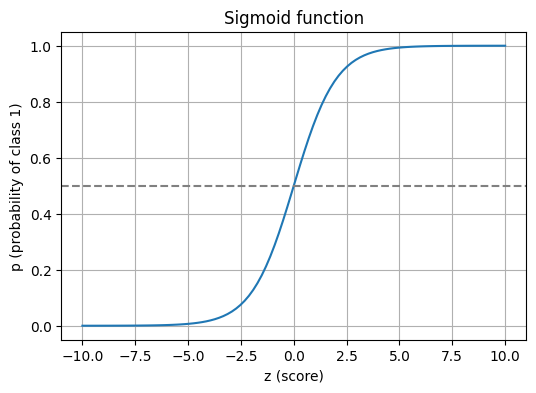

In [2]:
# Create 100 values of z between -10 and 10
z = np.linspace(-10, 10, 100)

# Apply the sigmoid formula
p = 1 / (1 + np.exp(-z))

plt.figure(figsize=(6, 4))
plt.plot(z, p)
plt.axhline(0.5, color="gray", linestyle="--")   # the 0.5 decision line
plt.xlabel("z (score)")
plt.ylabel("p (probability of class 1)")
plt.title("Sigmoid function")
plt.grid(True)
plt.show()

In [3]:
# Try a few values yourself
for value in [-5, -1, 0, 1, 5]:
    prob = 1 / (1 + np.exp(-value))
    print("z =", value, "  ->  p =", round(prob, 3))

z = -5   ->  p = 0.007
z = -1   ->  p = 0.269
z = 0   ->  p = 0.5
z = 1   ->  p = 0.731
z = 5   ->  p = 0.993


**What to notice:**
- A large negative score gives a probability close to **0**.
- A score of exactly **0** gives a probability of **0.5** (the model is unsure).
- A large positive score gives a probability close to **1**.

## 3. The dataset: student suitability

A university wants to predict whether a student is **suitable** for its Machine Learning track.
We have records of **80 students**. Each row is one student.

| Column | Meaning |
|---|---|
| `math_score` | Math exam score (40 to 100) |
| `programming_score` | Programming exam score (40 to 100) |
| `statistics_score` | Statistics exam score (40 to 100) |
| `attendance_pct` | Class attendance in percent (50 to 100) |
| `study_hours_week` | Self-study hours per week (0 to 20) |
| `sleep_hours` | Sleep hours per night |
| `phone_hours_day` | Phone screen time per day |
| `distance_km` | Distance from home to campus in km |
| `siblings` | Number of brothers and sisters |
| `age` | Age in years |
| `sport_hours_week` | Sport hours per week |
| `part_time_job_hours` | Part-time job hours per week |
| **`suitable`** | **Target: 1 = suitable, 0 = not suitable** |

The first five columns really affect suitability. The other seven are **not useful** for the prediction.
We include them on purpose, because real datasets often contain columns that do not help, and we want to see how the model deals with them.

Run the next cell to create the dataset. You do not need to understand every line of it; just run it.

In [4]:
rng = np.random.default_rng(13)    # fixed seed, so everyone gets exactly the same data
n = 80                             # number of students

df = pd.DataFrame({
    "math_score":          rng.integers(40, 101, n),
    "programming_score":   rng.integers(40, 101, n),
    "statistics_score":    rng.integers(40, 101, n),
    "attendance_pct":      rng.integers(50, 101, n),
    "study_hours_week":    rng.integers(0, 21, n),
    "sleep_hours":         rng.integers(4, 10, n),
    "phone_hours_day":     rng.integers(1, 9, n),
    "distance_km":         rng.integers(1, 31, n),
    "siblings":            rng.integers(0, 5, n),
    "age":                 rng.integers(18, 25, n),
    "sport_hours_week":    rng.integers(0, 11, n),
    "part_time_job_hours": rng.integers(0, 21, n),
})

# Hidden rule used to create the labels (the model will NOT see this rule, it must learn it)
score = (0.12 * (df["math_score"] - 70)
         + 0.10 * (df["programming_score"] - 70)
         + 0.06 * (df["statistics_score"] - 70)
         + 0.06 * (df["attendance_pct"] - 75)
         + 0.20 * (df["study_hours_week"] - 10))
probability = 1 / (1 + np.exp(-score))
df["suitable"] = (rng.random(n) < probability).astype(int)

print("Dataset created")

Dataset created


### 3.1 Look at the data

In [5]:
# First 5 rows
df.head()

,math_score,programming_score,statistics_score,attendance_pct,study_hours_week,sleep_hours,phone_hours_day,distance_km,siblings,age,sport_hours_week,part_time_job_hours,suitable
0,94,49,78,78,6,5,2,3,0,20,6,19,1
1,92,80,73,73,11,5,7,7,2,18,10,10,1
2,90,77,84,94,17,9,1,20,1,18,9,2,1
3,92,67,61,58,0,4,3,11,1,19,4,8,1
4,44,68,60,97,11,7,6,5,0,18,2,1,0


In [7]:
# Number of rows and columns
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (80, 13)


In [8]:
# How many students are in each class?
df["suitable"].value_counts()

,count
suitable,
1,51
0,29


The two classes are roughly balanced, which is good: the model sees enough examples of both.

Let us plot two of the useful features. Each dot is a student.

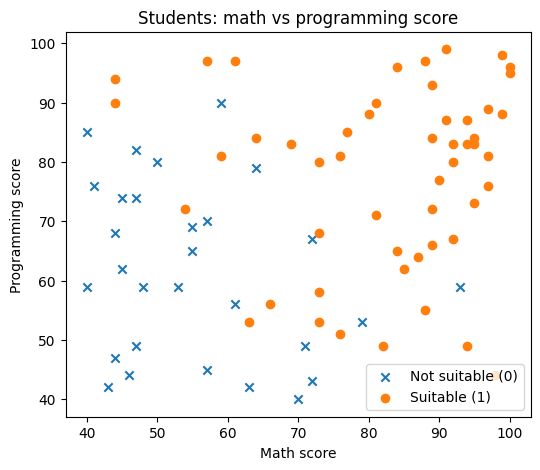

In [9]:
suitable = df[df["suitable"] == 1]
not_suitable = df[df["suitable"] == 0]

plt.figure(figsize=(6, 5))
plt.scatter(not_suitable["math_score"], not_suitable["programming_score"], marker="x", label="Not suitable (0)")
plt.scatter(suitable["math_score"], suitable["programming_score"], marker="o", label="Suitable (1)")
plt.xlabel("Math score")
plt.ylabel("Programming score")
plt.title("Students: math vs programming score")
plt.legend()
plt.show()

Students with higher math and programming scores are mostly suitable, but the groups overlap.
That overlap is normal: other features (statistics score, attendance, study hours) also matter.

## 4. Prepare the data

### 4.1 Separate features (X) and target (y)

- **X** = the input columns (everything except `suitable`).
- **y** = the column we want to predict (`suitable`).

In [10]:
X = df.drop(columns="suitable")    # all columns except the target
y = df["suitable"]                 # only the target

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (80, 12)
y shape: (80,)


### 4.2 Split into training and test sets

- The **training set** is used to teach the model.
- The **test set** is kept hidden during training. We use it at the end to check how well the model works on **new** students.

We use 70% for training and 30% for testing. `random_state=42` makes the split the same every time.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Training students:", len(X_train))
print("Test students:    ", len(X_test))

### 4.3 Scale the features

Our columns have very different ranges: `math_score` goes up to 100, while `siblings` goes up to 4.
`StandardScaler` changes every column so that it has an average of 0 and a similar spread.

Why this matters:
- The model trains more easily.
- Regularization (later in this lab) treats all weights fairly only when the features are on the same scale.

**Important rule:** we `fit` the scaler on the **training** data only, then use it to `transform` both sets.
The test set must stay "unseen".

In [ ]:
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)   # learn the scaling from training data, then apply it
X_test_s = scaler.transform(X_test)         # apply the same scaling to the test data

print("First training row before scaling:")
print(X_train.iloc[0].values)
print("\nFirst training row after scaling:")
print(X_train_s[0].round(2))

## 5. Model 1: Logistic regression WITHOUT regularization

In scikit-learn, the strength of regularization is controlled by a parameter called **`C`**.
We will explain `C` properly in Section 7. For now, just remember:

- A **very large** `C` (like 1,000,000) means **almost no regularization**.

`max_iter=1000` simply gives the training algorithm enough steps to finish.

In [ ]:
model_none = LogisticRegression(C=1000000, max_iter=1000)   # almost no regularization
model_none.fit(X_train_s, y_train)                          # train the model

print("Model trained")

### 5.1 Make predictions

- `predict()` gives the class (0 or 1).
- `predict_proba()` gives the probability of each class. Column 1 is the probability of class 1 (suitable).

In [ ]:
y_pred_none = model_none.predict(X_test_s)

print("Predicted:", y_pred_none[:10])
print("Actual:   ", y_test.values[:10])

In [ ]:
# Probability of being suitable for the first 5 test students
probs = model_none.predict_proba(X_test_s)[:5, 1]
print(probs.round(3))

### 5.2 Evaluate the model

**Accuracy** = number of correct predictions divided by the total number of predictions.

We calculate it on **both** the training set and the test set. Comparing the two tells us a lot.

In [ ]:
train_acc_none = accuracy_score(y_train, model_none.predict(X_train_s))
test_acc_none = accuracy_score(y_test, y_pred_none)

print("Training accuracy:", round(train_acc_none, 2))
print("Test accuracy:    ", round(test_acc_none, 2))

**What to notice:** the training accuracy is very high (close to 1.00, that is 100%), but the test accuracy is much lower.
The model does well on students it has already seen, and noticeably worse on new students. Keep this in mind; we come back to it in Section 6.

### 5.4 Classification report

- **Precision:** of the students the model *said* are suitable, how many really are?
- **Recall:** of the students who *really* are suitable, how many did the model find?
- **F1-score:** one number that combines precision and recall (higher is better).
- **Support:** how many test students are in each class.

In [ ]:
print(classification_report(y_test, y_pred_none, target_names=["Not suitable", "Suitable"]))

### 5.5 Look at the learned weights (coefficients)

Each feature gets one weight.
- A **positive** weight pushes the prediction towards *suitable*.
- A **negative** weight pushes it towards *not suitable*.
- A weight near **0** means the feature has little effect.

In [ ]:
weights_none = pd.Series(model_none.coef_[0], index=X.columns)
print(weights_none.round(2))

In [ ]:
weights_none.plot(kind="barh", figsize=(7, 5))
plt.axvline(0, color="black")
plt.title("Weights WITHOUT regularization")
plt.xlabel("Weight value")
plt.show()

**What to notice:** some of the useless columns (like `siblings`, `distance_km` or `age`) received **large** weights.
These columns have no real connection to suitability, so the model is learning patterns that exist only by chance in the 56 training students.

## 6. The problem: overfitting

**Overfitting** happens when a model learns the training data *too well*, including its random noise,
and therefore performs worse on new data.

**Analogy:** a student who memorises the answers to last year's exam paper gets 100% on that paper,
but struggles on this year's exam with new questions. The student memorised; they did not understand.

**Signs of overfitting:**
- Training accuracy is much higher than test accuracy (a big gap).
- The model gives large weights to features that should not matter.

Our Model 1 shows both signs. Regularization is a tool that fights overfitting.

## 7. Regularization

### 7.1 The idea

During training, the model tries to make its error as small as possible.
With regularization, we add a **penalty for large weights**:

$$\text{Total cost} = \text{Prediction error} + \lambda \times (b_1^2 + b_2^2 + \dots + b_n^2)$$

- The model now has two goals: make few mistakes **and** keep the weights small.
- A feature only gets a large weight if it is *really* useful.
- Weights of useless features are pushed towards 0.
- $\lambda$ (lambda) controls how strong the penalty is.

This is called **L2 regularization** (or *Ridge*). It is the default in scikit-learn.
(There is also **L1 regularization**, or *Lasso*, which uses the absolute values of the weights and can make some weights exactly 0. In this lab we use L2.)

### 7.2 The `C` parameter in scikit-learn

scikit-learn does not use $\lambda$ directly. It uses **`C`**, which is the **opposite** of $\lambda$:

$$C = \frac{1}{\lambda}$$

| `C` value | Regularization | What can happen |
|---|---|---|
| Very large (e.g. 1,000,000) | Almost none | Overfitting |
| Medium (e.g. 0.1 to 1) | Moderate | Usually a good balance |
| Very small (e.g. 0.001) | Very strong | Underfitting (the model becomes too simple) |

**Easy way to remember:** *small C = strong regularization*.

Note: the default value in scikit-learn is `C=1.0`, so `LogisticRegression()` already uses some regularization unless you change `C`.

## 8. Model 2: Logistic regression WITH regularization

We use the **same data** and the **same split**. The only change is `C=0.1`.

In [ ]:
model_reg = LogisticRegression(C=0.1, max_iter=1000)   # regularization is ON
model_reg.fit(X_train_s, y_train)

y_pred_reg = model_reg.predict(X_test_s)

train_acc_reg = accuracy_score(y_train, model_reg.predict(X_train_s))
test_acc_reg = accuracy_score(y_test, y_pred_reg)

print("Training accuracy:", round(train_acc_reg, 2))
print("Test accuracy:    ", round(test_acc_reg, 2))

**What to notice:** the training accuracy went **down** a little, but the test accuracy went **up**.
That is exactly what we want: the model memorises less and generalises better to new students.

In [ ]:
print(classification_report(y_test, y_pred_reg, target_names=["Not suitable", "Suitable"]))

## 9. How do we choose a good value of C?

We try several values of `C`, train one model for each, and record the training and test accuracy.

In [ ]:
C_values = [0.01, 0.03, 0.1, 0.3, 1, 10, 100, 1000000]

train_scores = []
test_scores = []

for c in C_values:
    model = LogisticRegression(C=c, max_iter=1000)
    model.fit(X_train_s, y_train)
    train_scores.append(accuracy_score(y_train, model.predict(X_train_s)))
    test_scores.append(accuracy_score(y_test, model.predict(X_test_s)))

results = pd.DataFrame({
    "C": C_values,
    "Train accuracy": train_scores,
    "Test accuracy": test_scores,
})
results.round(2)

In [ ]:
labels = [str(c) for c in C_values]    # use C values as text labels on the x-axis

plt.figure(figsize=(8, 4))
plt.plot(labels, train_scores, marker="o", label="Train accuracy")
plt.plot(labels, test_scores, marker="o", label="Test accuracy")
plt.xlabel("C  (left = strong regularization, right = almost none)")
plt.ylabel("Accuracy")
plt.title("Effect of C on accuracy")
plt.legend()
plt.grid(True)
plt.show()

**How to read this plot:**
- **Left side (very small C):** regularization is too strong. The model is too simple, so both accuracies are lower. This is **underfitting**.
- **Right side (very large C):** almost no regularization. Training accuracy is high, test accuracy drops. This is **overfitting**.
- **Middle:** the best balance. Here the test accuracy is highest around `C = 0.1`.

*Note for later courses:* in real projects we should not pick `C` using the test set. We would use a separate *validation set* or *cross-validation*. We use the test set here only to keep this first lab simple.

## 10. Before vs after: comparing the weights

In [ ]:
weights = pd.DataFrame({
    "Without regularization": model_none.coef_[0],
    "With regularization": model_reg.coef_[0],
}, index=X.columns)

weights.round(2)

In [ ]:
weights.plot(kind="barh", figsize=(8, 6))
plt.axvline(0, color="black")
plt.title("Weights before and after regularization")
plt.xlabel("Weight value")
plt.show()

**What to notice:**
- With regularization, **all weights are much smaller**.
- The largest weights now belong to `math_score` and `programming_score`, which really do affect suitability.
- Most of the useless features (`siblings`, `sport_hours_week`, `part_time_job_hours`, `phone_hours_day`, `distance_km`) are now very close to 0.
- Regularization is not perfect: a few useless features (for example `sleep_hours`) still keep a small weight, because our training set has only 56 students.

## 11. Before vs after: final comparison table

In [ ]:
comparison = pd.DataFrame({
    "Model": ["Without regularization (C=1000000)", "With regularization (C=0.1)"],
    "Train accuracy": [train_acc_none, train_acc_reg],
    "Test accuracy": [test_acc_none, test_acc_reg],
})
comparison["Gap (train - test)"] = comparison["Train accuracy"] - comparison["Test accuracy"]

comparison.round(2)

The regularized model has a **higher test accuracy** and a **much smaller gap** between training and test accuracy.
A small gap means the model behaves on new students almost as well as on the students it was trained on.

## 12. Using the model for a new student

A new student applies. Let us ask both models for a prediction.
The new data must go through the **same scaler** before it goes into the model.

In [ ]:
new_student = pd.DataFrame([{
    "math_score": 78,
    "programming_score": 72,
    "statistics_score": 65,
    "attendance_pct": 85,
    "study_hours_week": 12,
    "sleep_hours": 7,
    "phone_hours_day": 4,
    "distance_km": 10,
    "siblings": 2,
    "age": 20,
    "sport_hours_week": 3,
    "part_time_job_hours": 5,
}])

new_student_s = scaler.transform(new_student)    # same scaling as the training data

p_none = model_none.predict_proba(new_student_s)[0, 1]
p_reg = model_reg.predict_proba(new_student_s)[0, 1]

print("Without regularization: probability suitable =", round(p_none, 2))
print("With regularization:    probability suitable =", round(p_reg, 2))

Notice that the regularized model usually gives a **less extreme** probability (closer to 0.5).
Smaller weights make the model less over-confident.

## 13. Summary of Session 1

1. **Logistic regression** computes a score from the features and turns it into a probability with the **sigmoid** function. If the probability is 0.5 or more, it predicts class 1.
2. We always split data into **training** and **test** sets, and we fit the scaler on the training data only.
3. We evaluate with **accuracy**, and the **classification report** (precision, recall, F1).
4. **Overfitting**: high training accuracy, lower test accuracy, large weights on useless features.
5. **Regularization** adds a penalty for large weights. In scikit-learn, it is controlled by **`C`**: *small C = strong regularization*.
6. After regularization: training accuracy may drop slightly, **test accuracy improves**, the gap shrinks, and weights become smaller.

**Code pattern to remember for Session 2:**
```python
model = LogisticRegression(C=0.1, max_iter=1000)
model.fit(X_train_s, y_train)
y_pred = model.predict(X_test_s)
accuracy_score(y_test, y_pred)
```

---
# SESSION 2: Graded Exercises (100 marks)


**Task:** You will build a **spam detector**. You will repeat the steps from Session 1 on a new dataset: train a model without regularization, then with regularization, and compare the results.


**Instructions:**
1. Run the **Setup** cell first.
2. In each code cell, replace every `___` (three underscores) with the correct code. Do not change other lines.
3. For written questions, double-click the answer cell and type your answer.
4. Run every cell so its output is visible. Cells without output will not receive marks.
5. Do not change `random_state` values.

| Exercise | Topic | Marks |
|---|---|---|
| 1 | Explore the data | 15 |
| 2 | Prepare the data | 20 |
| 3 | Model without regularization | 25 |
| 4 | Apply regularization | 25 |
| 5 | Compare before and after | 15 |
| | **Total** | **100** |

## Setup (run this cell first, no marks)

This cell clears everything from Session 1, imports the libraries again and creates the spam dataset.

The dataset has **90 emails**. Each row is one email.

| Column | Meaning |
|---|---|
| `num_links` | Number of links in the email |
| `num_capital_words` | Number of words written in CAPITAL letters |
| `num_exclamations` | Number of "!" characters |
| `count_free` | How many times the word "free" appears |
| `count_win` | How many times the word "win" appears |
| `count_money` | How many times the word "money" appears |
| `count_meeting` | How many times the word "meeting" appears |
| `count_report` | How many times the word "report" appears |
| `email_length` | Number of words in the email |
| `num_recipients` | Number of people the email was sent to |
| `num_attachments` | Number of attached files |
| `hour_sent` | Hour of the day the email was sent (0 to 23) |
| `num_images` | Number of images in the email |
| `count_thanks` | How many times the word "thanks" appears |
| **`is_spam`** | **Target: 1 = spam, 0 = not spam** |

In [11]:
%reset -f

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

rng = np.random.default_rng(1)
n = 90
is_spam = (rng.random(n) < 0.4).astype(int)

def count_words(avg_normal, avg_spam):
    # spam emails get a different average count than normal emails
    return np.where(is_spam == 1, rng.poisson(avg_spam, n), rng.poisson(avg_normal, n))

spam_df = pd.DataFrame({
    "num_links":         count_words(1.0, 2.5),
    "num_capital_words": count_words(3, 6),
    "num_exclamations":  count_words(0.8, 2.0),
    "count_free":        count_words(0.3, 1.2),
    "count_win":         count_words(0.2, 0.9),
    "count_money":       count_words(0.3, 1.0),
    "count_meeting":     count_words(1.0, 0.4),
    "count_report":      count_words(0.8, 0.3),
    "email_length":      rng.integers(20, 400, n),
    "num_recipients":    rng.integers(1, 10, n),
    "num_attachments":   rng.integers(0, 4, n),
    "hour_sent":         rng.integers(0, 24, n),
    "num_images":        rng.integers(0, 5, n),
    "count_thanks":      rng.integers(0, 4, n),
})
spam_df["is_spam"] = is_spam

print("Spam dataset created. Start the exercises.")

Spam dataset created. Start the exercises.


## Exercise 1: Explore the data (15 marks)

**(a)** Show the first 5 rows of `spam_df`. **(5 marks)**
**(b)** Print the shape (rows, columns) of `spam_df`. **(5 marks)**
**(c)** Count how many emails are spam and how many are not spam. **(5 marks)**

In [13]:
# (a) First 5 rows
spam_df.head()

,num_links,num_capital_words,num_exclamations,count_free,count_win,count_money,count_meeting,count_report,email_length,num_recipients,num_attachments,hour_sent,num_images,count_thanks,is_spam
0,1,2,0,0,1,0,0,2,59,4,2,13,4,1,0
1,0,2,0,0,1,1,0,2,361,7,3,6,0,3,0
2,2,7,5,2,0,1,0,0,157,9,2,19,3,0,1
3,3,4,2,1,0,0,1,0,310,5,2,3,4,0,0
4,5,10,4,1,1,1,0,0,29,2,1,3,3,3,1


In [14]:
# (b) Shape
print("Shape:", spam_df.shape)

Shape: (90, 15)


In [15]:
# (c) Count of each class
spam_df["is_spam"].value_counts()

,count
is_spam,
0,59
1,31


## Exercise 2: Prepare the data (20 marks)

**(a)** Create `X` (all columns except the target) and `y` (only the target). **(5 marks)**
**(b)** Split the data: 30% for testing, `random_state=42`. **(10 marks)**
**(c)** Scale the features with `StandardScaler`. Remember: *fit* on training data, only *transform* test data. **(5 marks)**

In [16]:
# (a) Features and target
X = spam_df.drop(columns="is_spam")
y = spam_df["is_spam"]

# (b) Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# (c) Scaling
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Training emails:", len(X_train))
print("Test emails:", len(X_test))

Training emails: 63
Test emails: 27


## Exercise 3: Model WITHOUT regularization (25 marks)

**(a)** Create a logistic regression model with almost no regularization (`C=1000000`, `max_iter=1000`) and train it. **(10 marks)**
**(b)** Calculate and print the training accuracy and the test accuracy. **(10 marks)**
**(c)** Written question: is this model overfitting? Explain using your two accuracy numbers. **(5 marks)**

In [18]:
# (a) Create and train the model
model_none = LogisticRegression(C=1000000, max_iter=1000)
model_none.fit(X_train_s, y_train)

# (b) Accuracy on training and test data
train_acc_none = accuracy_score(y_train, model_none.predict(X_train_s))
test_acc_none = accuracy_score(y_test, model_none.predict(X_test_s))

print("Training accuracy:", round(train_acc_none, 2))
print("Test accuracy:", round(test_acc_none, 2))

Training accuracy: 1.0
Test accuracy: 0.67


**(c) Your answer:** Yes, the model is overfitting. The training accuracy is 1.0 (100%), which means it perfectly memorized the training data, while the test accuracy is much lower at 0.67 (67%). This large performance gap of 0.33 is a classic sign of overfitting.

## Exercise 4: Apply regularization (25 marks)

**(a)** Complete the loop that trains one model for each value of `C` and stores the training and test accuracy. **(10 marks)**
**(b)** Complete the plot of training and test accuracy against `C`. **(5 marks)**
**(c)** Look at your table and plot. Set `best_C` to the value with the **highest test accuracy**. Train the final model, print its accuracies. **(10 marks)**

In [17]:
# (a) Try different values of C
C_values = [0.01, 0.1, 1, 10, 100]

train_scores = []
test_scores = []

for c in C_values:
    model = LogisticRegression(C=c, max_iter=1000)
    model.fit(X_train_s, y_train)
    train_scores.append(accuracy_score(y_train, model.predict(X_train_s)))
    test_scores.append(accuracy_score(y_test, model.predict(X_test_s)))

results = pd.DataFrame({"C": C_values, "Train accuracy": train_scores, "Test accuracy": test_scores})
display(results.round(2))

,C,Train accuracy,Test accuracy
0,0.01,0.75,0.70
1,0.10,0.94,0.89
2,1.00,0.97,0.78
3,10.00,0.98,0.78
4,100.00,1.00,0.70


In [ ]:
# (b) Plot
labels = [str(c) for c in C_values]

plt.figure(figsize=(7, 4))
plt.plot(labels, train_scores, marker="o", label="Train accuracy")
plt.plot(labels, test_scores, marker="o", label="Test accuracy")
plt.xlabel("C")
plt.ylabel("Accuracy")
plt.title("Spam detection: effect of C")
plt.legend()
plt.grid(True)
plt.show()

In [19]:
# (c) Final regularized model
best_C = 0.1

model_reg = LogisticRegression(C=best_C, max_iter=1000)
model_reg.fit(X_train_s, y_train)

train_acc_reg = accuracy_score(y_train, model_reg.predict(X_train_s))
test_acc_reg = accuracy_score(y_test, model_reg.predict(X_test_s))

print("Best C:", best_C)
print("Training accuracy:", round(train_acc_reg, 2))
print("Test accuracy:", round(test_acc_reg, 2))

Best C: 0.1
Training accuracy: 0.94
Test accuracy: 0.89


## Exercise 5: Compare before and after (15 marks)

**(a)** Complete the comparison table of the two models. **(5 marks)**
**(b)** Complete the table of weights (coefficients) for the two models. **(5 marks)**
**(c)** Written question: in 2 to 3 sentences, describe what changed after regularization (accuracy and weights), and say which model you would use to filter real emails and why. **(5 marks)**

In [20]:
# (a) Comparison table
comparison = pd.DataFrame({
    "Model": ["Without regularization", "With regularization"],
    "Train accuracy": [train_acc_none, train_acc_reg],
    "Test accuracy": [test_acc_none, test_acc_reg],
})
comparison["Gap (train - test)"] = comparison["Train accuracy"] - comparison["Test accuracy"]
comparison.round(2)

,Model,Train accuracy,Test accuracy,Gap (train - test)
0,Without regularization,1.00,0.67,0.33
1,With regularization,0.94,0.89,0.05


In [21]:
# (b) Weights before and after
weights = pd.DataFrame({
    "Without regularization": model_none.coef_[0],
    "With regularization": model_reg.coef_[0],
}, index=X.columns)

weights.round(2)

,Without regularization,With regularization
num_links,14.15,0.38
num_capital_words,22.76,0.48
num_exclamations,1.01,0.35
count_free,-1.25,0.20
count_win,35.61,0.34
count_money,25.74,0.41
count_meeting,-7.97,-0.27
count_report,-7.51,-0.30
email_length,15.13,0.11
num_recipients,-19.65,-0.15


**(c) Your answer:** Regularization (C=0.1) reduced the training accuracy a bit from 1.00 to 0.94, while it significantly increased the test accuracy from 0.67 to 0.89. The gap between the training and test accuracies was reduced from 0.33 to only 0.05. Also, the extreme weights (coefficients) of the unregularized model (some over 30) were heavily penalized and shrunk to small realistic values near or under 0.5. If I were filtering real emails, I'd go for the regularized model, as it generalizes much better to unseen data and relies on more robust, stable patterns.